Predictions
[0 0] -> 0
[0 1] -> 0
[1 0] -> 0
[1 1] -> 1


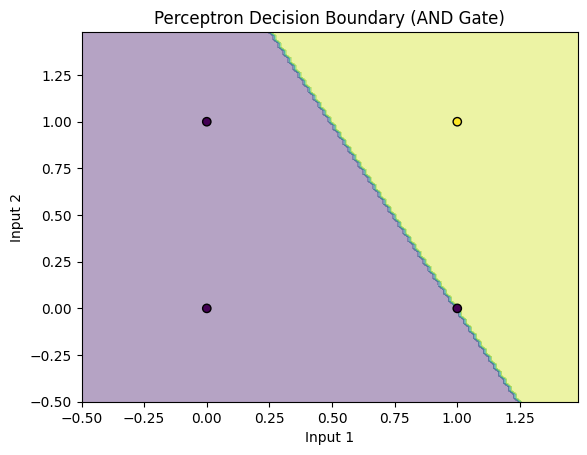

In [1]:
import numpy as np
import matplotlib.pyplot as plt

def step_function(x):
    if x >= 0:
        return 1
    return 0

class Perceptron:

    def __init__(self, input_size, learning_rate=0.1, epochs=10):
        self.weights = np.zeros(input_size + 1)
        self.lr = learning_rate
        self.epochs = epochs

    def predict(self, x):
        x = np.insert(x, 0, 1)
        weighted_sum = np.dot(self.weights, x)
        return step_function(weighted_sum)

    def train(self, X, y):

        for epoch in range(self.epochs):

            for xi, target in zip(X, y):

                prediction = self.predict(xi)

                error = target - prediction

                xi = np.insert(xi, 0, 1)

                self.weights += self.lr * error * xi

X = np.array([
    [0,0],
    [0,1],
    [1,0],
    [1,1]
])

y = np.array([0,0,0,1])

perceptron = Perceptron(input_size=2)

perceptron.train(X,y)

print("Predictions")

for x in X:
    print(x,"->",perceptron.predict(x))

x_min, x_max = -0.5, 1.5
y_min, y_max = -0.5, 1.5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.02),
    np.arange(y_min, y_max, 0.02)
)

Z = []

for i in range(len(xx.ravel())):
    point = np.array([xx.ravel()[i], yy.ravel()[i]])
    Z.append(perceptron.predict(point))

Z = np.array(Z).reshape(xx.shape)

plt.contourf(xx, yy, Z, alpha=0.4)
plt.scatter(X[:,0], X[:,1], c=y, edgecolors='black')
plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.title("Perceptron Decision Boundary (AND Gate)")
plt.show()